# M11 - Image classification and computer vision

**Level 3 · CPU-only · about 90 minutes · no download required**

This notebook trains a small convolutional network on the section's synthetic
shape dataset. The goal is not a benchmark score. It is to see the whole evidence
chain: source-grouped splits, a baseline, a training loop, per-class evaluation,
and the failure that a single accuracy number hides.

## Learning objectives

By the end of this notebook you can:

1. inspect image data as arrays, not as filenames;
2. verify that a split is grouped by source rather than by individual image;
3. train a small CNN with an explicit loop on CPU;
4. report accuracy, a confusion matrix, and per-class recall;
5. explain why a majority-class baseline matters;
6. inspect misclassified examples instead of guessing why the model failed.

## Prerequisites

- F03-F10: NumPy, pandas, splits, metrics.
- F11-F12: tensors, gradients, a training loop.
- Python 3.12 with `torch`, `numpy`, `pillow`, and `pandas`.
- CPU only; the model is deliberately small. No pretrained weights are downloaded.

## Conceptual explanation

An image classifier maps a tensor of pixel values to class scores. A convolution
shares weights across spatial positions, so the same edge detector is applied
everywhere. Pooling reduces spatial resolution. The classifier learns filters
from data; it does not know that a triangle is a shape until the loss and the
labels make that useful.

The most common invalid result is a high score caused by leakage. The synthetic
dataset renders three variants of each source shape. If variants of one source
appear in both training and test, the test set measures memorisation. The split
must group by `source_id`.

## Important terminology

| Term | Meaning |
| --- | --- |
| Tensor | A multidimensional numeric array; images are usually NCHW |
| Convolution | A learned local filter applied across an image |
| Receptive field | The input region that can affect one output feature |
| Epoch | One pass over the training set |
| Batch | A group of samples processed before one optimizer step |
| Confusion matrix | Counts of true class versus predicted class |
| Macro recall | Mean recall across classes, giving each class equal weight |
| Majority baseline | Accuracy from always predicting the most common class |


## 1. Set up imports and reproducibility


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
PROJECT = ROOT / "projects" / "computer-vision"
sys.path.insert(0, str(PROJECT))
print("Repository root:", ROOT.name)
print("Section package:", PROJECT.name)


Repository root: AITopics
Section package: computer-vision


In [2]:
import numpy as np
import pandas as pd
import torch
from PIL import Image
from IPython.display import display

from vision_core import dataio, models

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)

CLASSES = ["circle", "square", "triangle"]
print("torch:", torch.__version__)
print("device: cpu")


torch: 2.7.1+cpu
device: cpu


## 2. Load the grouped splits

`classification_splits()` returns arrays for train, validation, and test. It uses
a grouped split by source. The dataset is CC0-1.0 and generated by code, so there
is no download, personal data, or licence negotiation.


In [3]:
splits = dataio.classification_splits(seed=0)
for name in ("train", "val", "test"):
    images = splits[name]["images"]
    labels = splits[name]["labels"]
    print(name, "images:", images.shape, "labels:", np.bincount(labels, minlength=3))

counts = pd.DataFrame(
    {
        name: np.bincount(splits[name]["labels"], minlength=3)
        for name in ("train", "val", "test")
    },
    index=CLASSES,
)
counts


train images: (210, 32, 32, 3) labels: [69 75 66]
val images: (45, 32, 32, 3) labels: [18 12 15]
test images: (45, 32, 32, 3) labels: [15 12 18]


,train,val,test
circle,69,18,15
square,75,12,12
triangle,66,15,18


## 3. Look at the pixels

Before training, inspect a sample. Check the value range, the image size, and
whether the label agrees with what you see. A preprocessing bug is cheaper to
find here than after twenty epochs.


pixel range: 37 to 255
labels: ['triangle', 'triangle', 'triangle', 'triangle', 'triangle', 'triangle', 'circle', 'circle', 'circle', 'square', 'square', 'square']


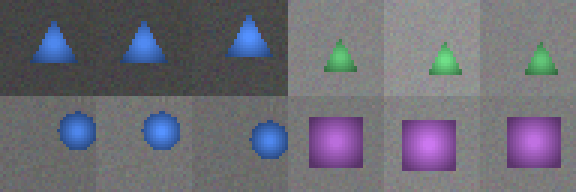

In [4]:
def image_grid(images, labels, columns=6, tile=96):
    rows = (len(images) + columns - 1) // columns
    canvas = Image.new("RGB", (columns * tile, rows * tile), "white")
    for index, (image, label) in enumerate(zip(images, labels)):
        tile_image = Image.fromarray(np.asarray(image, dtype=np.uint8)).resize(
            (tile, tile), Image.Resampling.NEAREST
        )
        canvas.paste(tile_image, ((index % columns) * tile, (index // columns) * tile))
    return canvas

sample_images = splits["train"]["images"][:12]
sample_labels = splits["train"]["labels"][:12]
print("pixel range:", int(sample_images.min()), "to", int(sample_images.max()))
print("labels:", [CLASSES[index] for index in sample_labels])
display(image_grid(sample_images, sample_labels))


## 4. Convert arrays to tensors

PyTorch convolution expects `NCHW`: batch, channel, height, width. The data is
NHWC. The conversion also scales 0-255 pixels to 0-1. Keep the validation and test
conversions identical; a mismatch here produces a model that looks broken for no
architectural reason.


In [5]:
def to_nchw(images):
    tensor = torch.from_numpy(np.asarray(images)).permute(0, 3, 1, 2).float()
    return tensor / 255.0

x_train = to_nchw(splits["train"]["images"])
y_train = torch.from_numpy(splits["train"]["labels"]).long()
x_val = to_nchw(splits["val"]["images"])
y_val = torch.from_numpy(splits["val"]["labels"]).long()
x_test = to_nchw(splits["test"]["images"])
y_test = torch.from_numpy(splits["test"]["labels"]).long()

print("train:", tuple(x_train.shape), "val:", tuple(x_val.shape), "test:", tuple(x_test.shape))


train: (210, 3, 32, 32) val: (45, 3, 32, 32) test: (45, 3, 32, 32)


## 5. Establish a baseline

Always compute the majority-class baseline before celebrating a model. If the
classes are balanced, the baseline is about one third. A model that cannot beat
that has learned nothing useful, even if its loss went down.


In [6]:
values, frequencies = np.unique(splits["test"]["labels"], return_counts=True)
majority_index = int(values[np.argmax(frequencies)])
majority_accuracy = float(np.max(frequencies) / len(splits["test"]["labels"]))
print("majority class:", CLASSES[majority_index])
print("majority baseline accuracy:", round(majority_accuracy, 3))


majority class: triangle
majority baseline accuracy: 0.4


## 6. Train the CNN

`TinyCNN` uses three convolution blocks, global average pooling, and a linear
classifier. Global pooling keeps the parameter count independent of image size.
The loop below makes every optimizer step visible: zero gradients, forward pass,
cross-entropy, backward pass, update.


In [7]:
model = models.TinyCNN(num_classes=3, width=16, dropout=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
loss_fn = torch.nn.CrossEntropyLoss()

history = []
for epoch in range(1, 13):
    model.train()
    order = torch.randperm(len(x_train))
    running_loss = 0.0
    batches = 0
    for start in range(0, len(order), 32):
        batch = order[start : start + 32]
        optimizer.zero_grad()
        logits = model(x_train[batch])
        loss = loss_fn(logits, y_train[batch])
        loss.backward()
        optimizer.step()
        running_loss += float(loss.item())
        batches += 1

    model.eval()
    with torch.no_grad():
        val_accuracy = float((model(x_val).argmax(dim=1) == y_val).float().mean())
    row = {
        "epoch": epoch,
        "train_loss": round(running_loss / batches, 4),
        "val_accuracy": round(val_accuracy, 3),
    }
    history.append(row)
    print(row)

pd.DataFrame(history)


{'epoch': 1, 'train_loss': 1.0466, 'val_accuracy': 0.4}
{'epoch': 2, 'train_loss': 0.8195, 'val_accuracy': 0.333}


{'epoch': 3, 'train_loss': 0.6436, 'val_accuracy': 0.333}
{'epoch': 4, 'train_loss': 0.59, 'val_accuracy': 0.4}


{'epoch': 5, 'train_loss': 0.4594, 'val_accuracy': 0.467}
{'epoch': 6, 'train_loss': 0.3599, 'val_accuracy': 0.467}


{'epoch': 7, 'train_loss': 0.3142, 'val_accuracy': 0.333}
{'epoch': 8, 'train_loss': 0.2667, 'val_accuracy': 0.622}


{'epoch': 9, 'train_loss': 0.1915, 'val_accuracy': 0.622}
{'epoch': 10, 'train_loss': 0.0993, 'val_accuracy': 0.333}


{'epoch': 11, 'train_loss': 0.0748, 'val_accuracy': 0.867}
{'epoch': 12, 'train_loss': 0.0472, 'val_accuracy': 0.867}


,epoch,train_loss,val_accuracy
0,1,1.0466,0.400
1,2,0.8195,0.333
2,3,0.6436,0.333
3,4,0.5900,0.400
4,5,0.4594,0.467
5,6,0.3599,0.467
6,7,0.3142,0.333
7,8,0.2667,0.622
8,9,0.1915,0.622
9,10,0.0993,0.333


## 7. Evaluate on the untouched test split

The test split was not used to choose the architecture, learning rate, or epoch
count. Evaluate once, then inspect the errors. If you tune against the test set,
it stops being a test set.


In [8]:
model.eval()
with torch.no_grad():
    logits = model(x_test)
    probabilities = torch.softmax(logits, dim=1)
    predictions = logits.argmax(dim=1)

accuracy = float((predictions == y_test).float().mean())
print("test accuracy:", round(accuracy, 3))
print("parameters:", models.count_parameters(model))
print("serialized size (MB):", round(models.model_size_mb(model), 4))

confusion = np.zeros((3, 3), dtype=int)
for truth, predicted in zip(y_test.numpy(), predictions.numpy()):
    confusion[truth, predicted] += 1

pd.DataFrame(confusion, index=[f"true {name}" for name in CLASSES], columns=[f"pred {name}" for name in CLASSES])


test accuracy: 0.867
parameters: 72499
serialized size (MB): 0.2897


,pred circle,pred square,pred triangle
true circle,12,3,0
true square,0,12,0
true triangle,3,0,15


## 8. Per-class metrics and confident errors

Overall accuracy is a weighted average. Per-class recall tells you which class
disappears. A confident error is more dangerous than an uncertain one because a
downstream system may trust it. This cell reports both without hiding the weak
class.


In [9]:
rows = []
for class_index, name in enumerate(CLASSES):
    support = int((y_test == class_index).sum())
    correct = int(((predictions == class_index) & (y_test == class_index)).sum())
    predicted_total = int((predictions == class_index).sum())
    rows.append(
        {
            "class": name,
            "support": support,
            "correct": correct,
            "recall": round(correct / support, 3) if support else None,
            "precision": round(correct / predicted_total, 3) if predicted_total else None,
        }
    )
pd.DataFrame(rows)


,class,support,correct,recall,precision
0,circle,15,12,0.800,0.8
1,square,12,12,1.000,0.8
2,triangle,18,15,0.833,1.0


In [10]:
confidence = probabilities.max(dim=1).values
errors = (predictions != y_test).nonzero(as_tuple=False).flatten()
error_rows = [
    {
        "index": int(index),
        "truth": CLASSES[int(y_test[index])],
        "prediction": CLASSES[int(predictions[index])],
        "confidence": round(float(confidence[index]), 3),
    }
    for index in errors[:10]
]
pd.DataFrame(error_rows)


,index,truth,prediction,confidence
0,6,circle,square,0.607
1,7,circle,square,0.569
2,8,circle,square,0.653
3,21,triangle,circle,0.621
4,22,triangle,circle,0.730
5,23,triangle,circle,0.757


## Explanation of the code

- `permute(0, 3, 1, 2)` changes NHWC to NCHW; it does not change the underlying
  values.
- The batch loop is explicit so you can see where gradients are cleared and where
  the optimizer updates weights.
- `model.eval()` disables dropout and changes normalization behaviour. It is not
  optional during evaluation.
- The confusion matrix counts every test sample exactly once.
- Per-class recall uses the true class count as the denominator; precision uses
  the predicted count. Reporting one without the other can hide a trade-off.

## Expected output

You should see 210/45/45 images, a pixel range of 0 to 255, a training table whose
validation accuracy rises above the roughly 0.33 majority baseline, a test
confusion matrix, and per-class rows. The seeded run stored here reports 0.867 test accuracy (39 of 45 images)
against a 0.40 majority baseline. That is a measured result from this CPU run,
not a benchmark or a guarantee. If you rerun on a different PyTorch
build, small differences are normal.

## Interpretation of results

On the stored seeded run the test accuracy is 0.867, compared with the
0.40 majority-class baseline; 39 of 45 test images are correct. That is a real
improvement, but the per-class table still shows a weak class, so the score is
necessary but not sufficient evidence of a useful model. Inspect which
class has the lowest recall and look at the misclassified images. If one class is
repeatedly confused with another, the next experiment should change one factor:
more examples, a different augmentation, a larger receptive field, or a longer
training budget. Do not change all four at once.

## Practical exercises

1. Train for 3 epochs and then 25 epochs. Plot or tabulate the validation accuracy
   and explain the difference.
2. Remove the `model.eval()` call before validation. Does the result change? Why?
3. Compute macro recall by hand from the per-class table and compare it with
   accuracy.
4. Shuffle the labels and retrain. The model should fall to the baseline; if it
   does not, your evaluation has a bug.

## Challenge

Train the same architecture on a random image split instead of the grouped split.
Report both test scores and the number of sources shared between train and test.
Explain which number you would put in a project report and why.

## Limitations

The dataset contains synthetic shapes, not photographs; 300 examples and a
12-epoch CPU run are enough to test the training loop, not to claim
state-of-the-art vision. The grouped split limits duplicate-source leakage but
cannot make the task representative. A single seed can move accuracy by several
points, and the small CNN has no pretrained features. Report the baseline, the
split policy, and the per-class errors with any score.

## Common mistakes and troubleshooting

| Symptom | Likely cause | Fix |
| --- | --- | --- |
| Shape error in convolution | NHWC passed instead of NCHW | Apply the documented permutation |
| Accuracy stays at baseline | Labels not converted to `long` | Inspect label dtype and class balance |
| Validation much worse than training | Dropout still active | Call `model.eval()` |
| Perfect test score | Split leaked sources or labels | Audit source ids and shuffle the labels as a control |
| All predictions one class | Learning rate too high or loss misconfigured | Lower the rate and print the logits once |
| Memory grows during training | Tensors kept in a Python list with gradients | Use `torch.no_grad()` for evaluation and detach logged values |

## Summary

You trained a CNN from raw pixels, evaluated it against a majority baseline, and
inspected per-class failures. The important artifact is the evidence chain: grouped
split, explicit loop, untouched test set, confusion matrix, and error examples.

## Further reading

- Stanford CS231n, "Convolutional Neural Networks" course notes.
- Goodfellow, Bengio, and Courville, *Deep Learning*, chapters 9 and 11.
- PyTorch tutorials: "Training a Classifier" and "Optimizing Model Parameters".
- The repository's `vision_core.models`, `vision_core.training`, and `tests/test_computer_vision.py`.
